Modules import

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import sklearn
import matplotlib.pyplot as plt

Dataset Loading

In [2]:
df = pd.read_csv("Data_for_UCI_named.csv")
pd.set_option('display.max_columns', None)
df

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.930406,9.487627,2.376523,6.187797,3.343416,-0.658054,-1.449106,-1.236256,0.601709,0.779642,0.813512,0.608385,0.023892,unstable
9996,3.392299,1.274827,2.954947,6.894759,4.349512,-1.663661,-0.952437,-1.733414,0.502079,0.567242,0.285880,0.366120,-0.025803,stable
9997,2.364034,2.842030,8.776391,1.008906,4.299976,-1.380719,-0.943884,-1.975373,0.487838,0.986505,0.149286,0.145984,-0.031810,stable
9998,9.631511,3.994398,2.757071,7.821347,2.514755,-0.966330,-0.649915,-0.898510,0.365246,0.587558,0.889118,0.818391,0.037789,unstable


In [3]:
df.describe()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.250000,5.250001,5.250004,5.249997,3.750000,-1.250000,-1.250000,-1.250000,0.525000,0.525000,0.525000,0.525000,0.015731
std,2.742548,2.742549,2.742549,2.742556,0.752160,0.433035,0.433035,0.433035,0.274256,0.274255,0.274255,0.274255,0.036919
min,0.500793,0.500141,0.500788,0.500473,1.582590,-1.999891,-1.999945,-1.999926,0.050009,0.050053,0.050054,0.050028,-0.080760
25%,2.874892,2.875140,2.875522,2.874950,3.218300,-1.624901,-1.625025,-1.624960,0.287521,0.287552,0.287514,0.287494,-0.015557
50%,5.250004,5.249981,5.249979,5.249734,3.751025,-1.249966,-1.249974,-1.250007,0.525009,0.525003,0.525015,0.525002,0.017142
75%,7.624690,7.624893,7.624948,7.624838,4.282420,-0.874977,-0.875043,-0.875065,0.762435,0.762490,0.762440,0.762433,0.044878
max,9.999469,9.999837,9.999450,9.999443,5.864418,-0.500108,-0.500072,-0.500025,0.999937,0.999944,0.999982,0.999930,0.109403


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB


In [5]:
df["stabf"].value_counts()

stabf
unstable    6380
stable      3620
Name: count, dtype: int64

In [6]:
df.isnull().sum()

tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64

<Axes: >

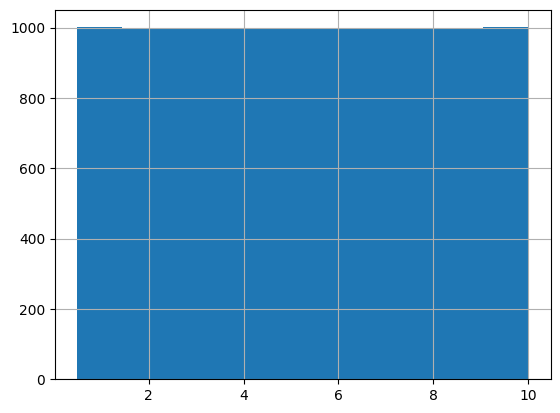

In [7]:
df["tau1"].hist()


<Axes: >

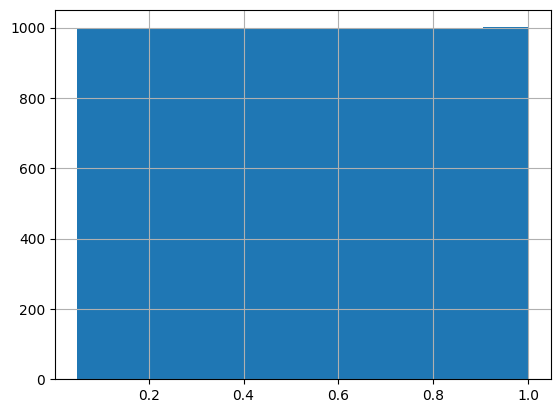

In [8]:
df["g1"].hist()

correlation


In [9]:
df.select_dtypes(include = 'number').corr()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
tau1,1.000000,0.015586,-0.005970,-0.017265,0.027183,-0.015485,-0.015924,-0.015807,0.010521,0.015350,-0.001279,0.005494,0.275761
tau2,0.015586,1.000000,0.014273,-0.001965,-0.004769,0.006573,0.007673,-0.005963,-0.001742,0.015383,0.016508,-0.011764,0.290975
tau3,-0.005970,0.014273,1.000000,0.004354,0.016953,-0.003134,-0.008780,-0.017531,-0.011605,0.007671,0.014702,-0.011497,0.280700
tau4,-0.017265,-0.001965,0.004354,1.000000,-0.003173,0.010553,0.006169,-0.011211,-0.004149,0.008431,0.003260,-0.000491,0.278576
p1,0.027183,-0.004769,0.016953,-0.003173,1.000000,-0.573157,-0.584554,-0.579239,0.000721,0.015405,0.001069,-0.015451,0.010278
p2,-0.015485,0.006573,-0.003134,0.010553,-0.573157,1.000000,0.002388,-0.006844,0.015603,-0.018032,0.007555,0.019817,0.006255
p3,-0.015924,0.007673,-0.008780,0.006169,-0.584554,0.002388,1.000000,0.012953,-0.003219,-0.011575,-0.005897,-0.010485,-0.003321
p4,-0.015807,-0.005963,-0.017531,-0.011211,-0.579239,-0.006844,0.012953,1.000000,-0.013636,0.002850,-0.003515,0.017505,-0.020786
g1,0.010521,-0.001742,-0.011605,-0.004149,0.000721,0.015603,-0.003219,-0.013636,1.000000,0.007559,-0.005836,0.012431,0.282774
g2,0.015350,0.015383,0.007671,0.008431,0.015405,-0.018032,-0.011575,0.002850,0.007559,1.000000,-0.012809,-0.014909,0.293601


<Axes: >

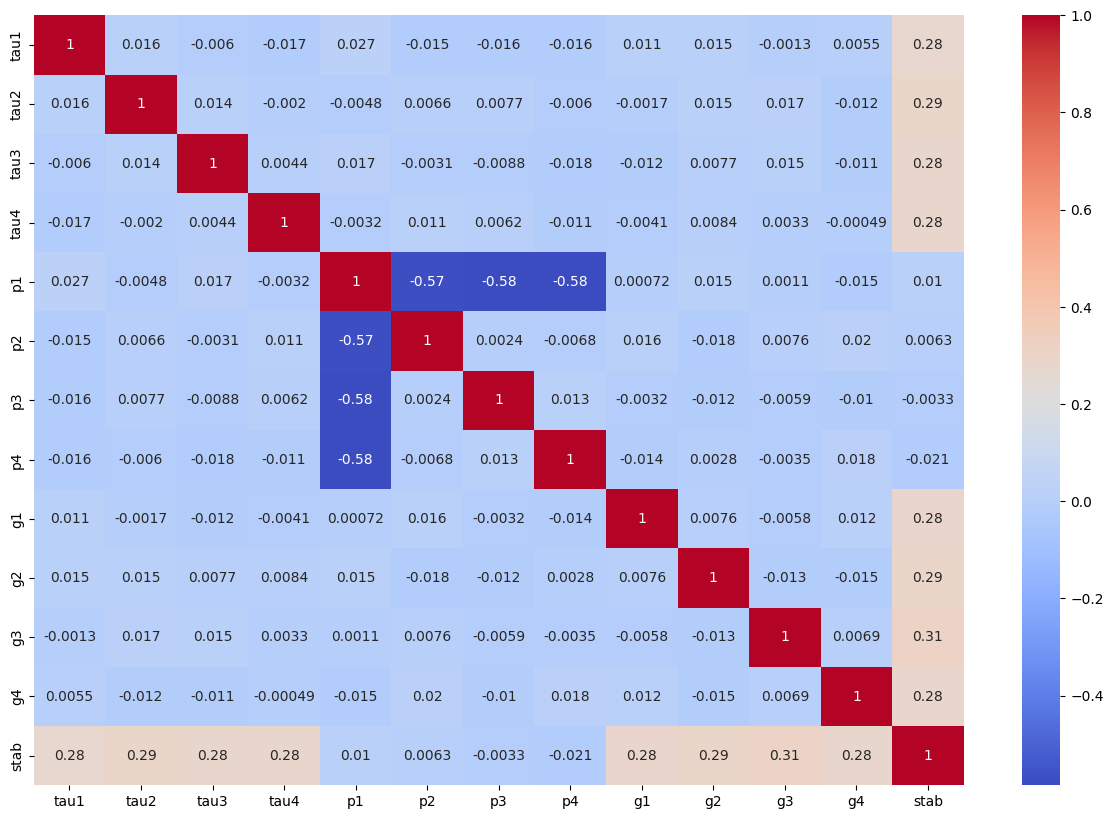

In [10]:
df.drop(columns = 'stab')
corr = df.select_dtypes(include = 'number').corr()
fig, ax = plt.subplots(figsize =(15,10))
sns.heatmap(corr, annot = True, ax=ax, cmap = 'coolwarm')

Label Encoding

In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [12]:
df['stabf'] = le.fit_transform(df['stabf'])
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,1
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,0
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,1
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,1
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,1


Model training

In [13]:
from sklearn.model_selection import train_test_split
X= df.drop(columns = ["stabf", "stab"])
Y = df['stabf']
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3)

Applying KNN

In [32]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()

In [33]:
model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [35]:
print("Accuraccy_KNN: ", model.score(x_test, y_test))

Accuraccy_KNN:  0.7826666666666666


Applying Random Forest

In [17]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)
model.fit(x_train, y_train)
print("Accuraccy: ", model.score(x_test, y_test))

Accuraccy:  0.9176666666666666


              precision    recall  f1-score   support

           0       0.92      0.85      0.88      1082
           1       0.92      0.96      0.94      1918

    accuracy                           0.92      3000
   macro avg       0.92      0.90      0.91      3000
weighted avg       0.92      0.92      0.92      3000

[[ 915  167]
 [  80 1838]]


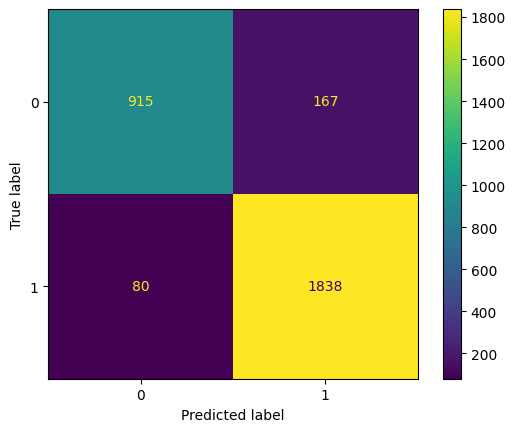

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [19]:
new_grid = pd.DataFrame([{
    "tau1": 2.5,
    "tau2": 3.0,
    "tau3": 4.0,
    "tau4": 2.0,
    "p1": 3.7,
    "p2": -1.0,
    "p3": -1.5,
    "p4": -1.2,
    "g1": 0.5,
    "g2": 0.6,
    "g3": 0.4,
    "g4": 0.7
}])

new_grid.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4
0,2.5,3.0,4.0,2.0,3.7,-1.0,-1.5,-1.2,0.5,0.6,0.4,0.7


In [20]:
print("Training columns:")
print(x_train.columns.tolist())

print("\nNew grid columns:")
print(new_grid.columns.tolist())

print("\nModel expects:")
print(model.feature_names_in_)

Training columns:
['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']

New grid columns:
['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']

Model expects:
['tau1' 'tau2' 'tau3' 'tau4' 'p1' 'p2' 'p3' 'p4' 'g1' 'g2' 'g3' 'g4']


In [21]:
prediction = model.predict(new_grid)
print("Predicted grid condition:", prediction[0])
if(prediction[0]==1):
    print("Predicted grid condition: Unstable")
else:
    print("Predicted grid condition: stable")   

Predicted grid condition: 0
Predicted grid condition: stable


In [22]:
probability = model.predict_proba(new_grid)
predicted_class = le.inverse_transform(prediction)[0]

print("Predicted grid condition:", predicted_class)

print("Probability of stable:",
      probability[0][list(le.classes_).index("stable")] * 100, "%")

print("Probability of unstable:",
      probability[0][list(le.classes_).index("unstable")] * 100, "%")

Predicted grid condition: stable
Probability of stable: 61.0 %
Probability of unstable: 39.0 %


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report


scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(x_train)

X_test_scaled = scaler.transform(x_test)


knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(X_train_scaled, y_train)


knn_pred = knn_model.predict(X_test_scaled)


print("KNN accuracy:", accuracy_score(y_test, knn_pred))

print(classification_report(y_test, knn_pred))

KNN accuracy: 0.8316666666666667
              precision    recall  f1-score   support

           0       0.82      0.68      0.75      1082
           1       0.84      0.92      0.87      1918

    accuracy                           0.83      3000
   macro avg       0.83      0.80      0.81      3000
weighted avg       0.83      0.83      0.83      3000



In [24]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

results = []

for k in range(1, 26):

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    pred = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, pred)

    results.append((k, accuracy))

for k, accuracy in results:
    print(f"K = {k}, Accuracy = {accuracy:.4f}")

K = 1, Accuracy = 0.8073
K = 2, Accuracy = 0.8023
K = 3, Accuracy = 0.8317
K = 4, Accuracy = 0.8443
K = 5, Accuracy = 0.8440
K = 6, Accuracy = 0.8530
K = 7, Accuracy = 0.8507
K = 8, Accuracy = 0.8603
K = 9, Accuracy = 0.8490
K = 10, Accuracy = 0.8620
K = 11, Accuracy = 0.8503
K = 12, Accuracy = 0.8607
K = 13, Accuracy = 0.8540
K = 14, Accuracy = 0.8653
K = 15, Accuracy = 0.8537
K = 16, Accuracy = 0.8630
K = 17, Accuracy = 0.8543
K = 18, Accuracy = 0.8663
K = 19, Accuracy = 0.8557
K = 20, Accuracy = 0.8690
K = 21, Accuracy = 0.8547
K = 22, Accuracy = 0.8690
K = 23, Accuracy = 0.8583
K = 24, Accuracy = 0.8677
K = 25, Accuracy = 0.8540


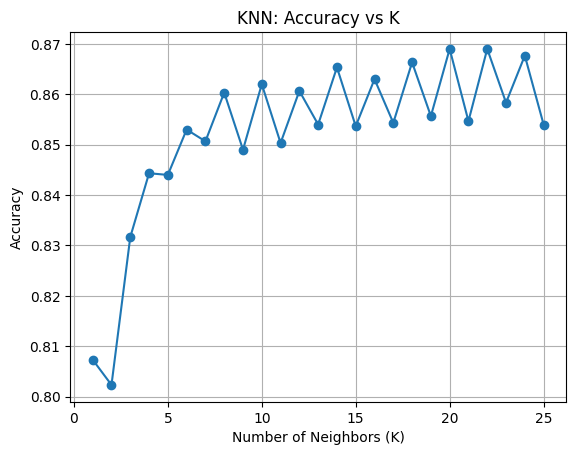

In [25]:
import matplotlib.pyplot as plt

k_values = [r[0] for r in results]
accuracies = [r[1] for r in results]

plt.plot(k_values, accuracies, marker='o')
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: Accuracy vs K")
plt.grid()
plt.show()

In [26]:
new_grid_scaled = scaler.transform(new_grid)

knn_prediction = knn_model.predict(new_grid_scaled)

print("KNN prediction:",
      le.inverse_transform(knn_prediction)[0])

KNN prediction: stable


In [27]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale')
)


svm_model.fit(x_train, y_train)


svm_pred = svm_model.predict(x_test)


print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

SVM Accuracy: 0.9556666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      1082
           1       0.96      0.97      0.97      1918

    accuracy                           0.96      3000
   macro avg       0.95      0.95      0.95      3000
weighted avg       0.96      0.96      0.96      3000


Confusion Matrix:
[[1007   75]
 [  58 1860]]


In [28]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


nb_model = GaussianNB()


nb_model.fit(x_train, y_train)


nb_pred = nb_model.predict(x_test)


print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))

Naive Bayes Accuracy: 0.8323333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.67      0.74      1082
           1       0.83      0.93      0.88      1918

    accuracy                           0.83      3000
   macro avg       0.83      0.80      0.81      3000
weighted avg       0.83      0.83      0.83      3000


Confusion Matrix:
[[ 720  362]
 [ 141 1777]]


In [29]:
prediction = nb_model.predict(new_grid)

predicted_class = le.inverse_transform(prediction)[0]

print("Predicted Grid Stability:", predicted_class)

Predicted Grid Stability: stable


In [30]:
print("Accuracy: ")
print("Random Forest: ", model.score(x_test, y_test))
print("KNN:", accuracy_score(y_test, knn_pred))
print("SVM:", accuracy_score(y_test, svm_pred))
print("Naive Bayes:", accuracy_score(y_test, nb_pred))

Accuracy: 
Random Forest:  0.9176666666666666
KNN: 0.8316666666666667
SVM: 0.9556666666666667
Naive Bayes: 0.8323333333333334


Showing The chart of Accuracy


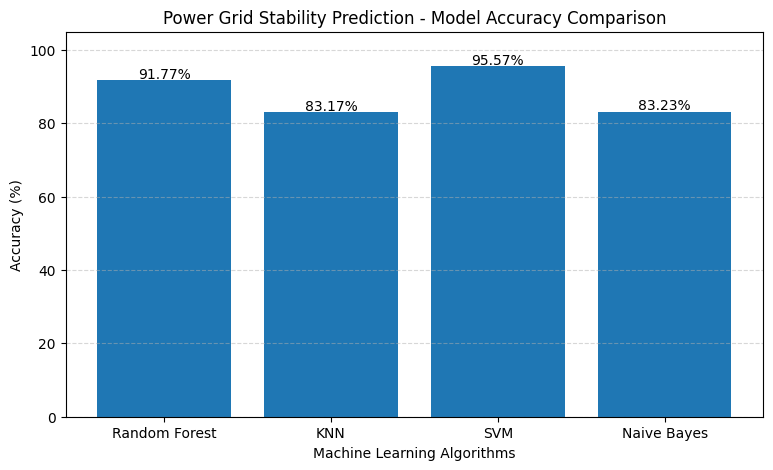

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


models = ['Random Forest', 'KNN', 'SVM', 'Naive Bayes']

accuracies = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, knn_pred),
    accuracy_score(y_test, svm_pred),
    accuracy_score(y_test, nb_pred)
]


accuracies = [acc * 100 for acc in accuracies]


plt.figure(figsize=(9, 5))

bars = plt.bar(models, accuracies)


for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f'{height:.2f}%',
        ha='center'
    )

plt.title('Power Grid Stability Prediction - Model Accuracy Comparison')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')

plt.ylim(0, 105)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()